In [10]:
%pip install seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [11]:
df = pd.read_csv('IMDb Movies India.csv', encoding='latin-1')#IMDb india dataset is usually encoded in latin-1 format, so we need to specify the encoding while reading the file.
print(df.shape)

df.head()
df.info()
print()
df.isnull().sum()



(15509, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15509 entries, 0 to 15508
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      15509 non-null  object 
 1   Year      14981 non-null  object 
 2   Duration  7240 non-null   object 
 3   Genre     13632 non-null  object 
 4   Rating    7919 non-null   float64
 5   Votes     7920 non-null   object 
 6   Director  14984 non-null  object 
 7   Actor 1   13892 non-null  object 
 8   Actor 2   13125 non-null  object 
 9   Actor 3   12365 non-null  object 
dtypes: float64(1), object(9)
memory usage: 1.2+ MB



Name           0
Year         528
Duration    8269
Genre       1877
Rating      7590
Votes       7589
Director     525
Actor 1     1617
Actor 2     2384
Actor 3     3144
dtype: int64

In [12]:
#cleaning the data
df = df.dropna(subset=['Rating']).copy() #cannot train without target so rating is what to predict. movie without rating has no ans to learn from  


In [13]:
#fixing year
#year look like (2019), which is text with bracket. \d{4} mean'finding 4 digit in row so (2019) becomes 2019.astype(float) then turn into numbers
df['Year']=df['Year'].str.extract(r'(\d{4})').astype(float)

In [14]:
#fixing duration - duration look like 109 min.d+ mean "grab the digit" so it becomes 109
df['Duration']=df['Duration'].str.extract(r'(\d+)').astype(float) 

In [15]:
#fixing votes- votes look likes 1,234 and the comma makes it text so 
#.str.replace(',','') turn into 1,234 into 1234 and pd.to_numeric(...) converts the text into real numbers and errors='coerce' means anthing that still cannot be converted becomes NaN 
df['Votes'] = pd.to_numeric(df['Votes'].astype(str).str.replace(',',''), errors='coerce') #removing commas from votes and converting it to numeric


In [16]:
#fill missing values with the median 
for c in ['Year', 'Duration',"Votes"]:
        df[c]= df[c].fillna(df[c].median())

#fill missing values
for c in [ 'Genre', 'Director', 'Actor 1', 'Actor 2','Actor 3']:
          df[c]=df[c].fillna('Unknown')


#main genre only
df['Genre1'] = df['Genre'].str.split(',').str[0].str.strip() #split the genre by comma and take the first genre and remove any leading or trailing whitespace

print(df.shape)
print(df.isnull().sum())
df.head()

          

(7919, 11)
Name        0
Year        0
Duration    0
Genre       0
Rating      0
Votes       0
Director    0
Actor 1     0
Actor 2     0
Actor 3     0
Genre1      0
dtype: int64


,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3,Genre1
1,#Gadhvi (He thought he was Gandhi),2019.0,109.0,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid,Drama
3,#Yaaram,2019.0,110.0,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor,Comedy
5,...Aur Pyaar Ho Gaya,1997.0,147.0,"Comedy, Drama, Musical",4.7,827,Rahul Rawail,Bobby Deol,Aishwarya Rai Bachchan,Shammi Kapoor,Comedy
6,...Yahaan,2005.0,142.0,"Drama, Romance, War",7.4,1086,Shoojit Sircar,Jimmy Sheirgill,Minissha Lamba,Yashpal Sharma,Drama
8,?: A Question Mark,2012.0,82.0,"Horror, Mystery, Thriller",5.6,326,Allyson Patel,Yash Dave,Muntazir Ahmad,Kiran Bhatia,Horror


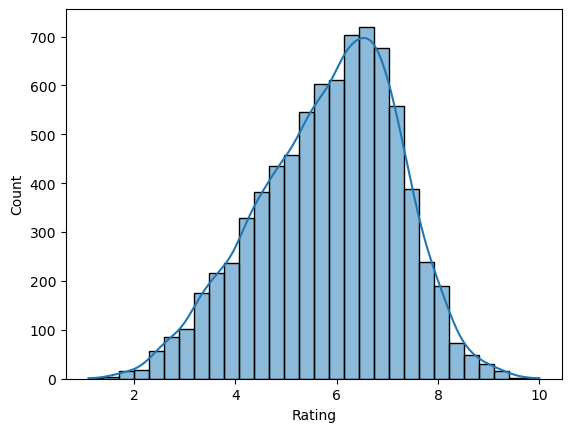

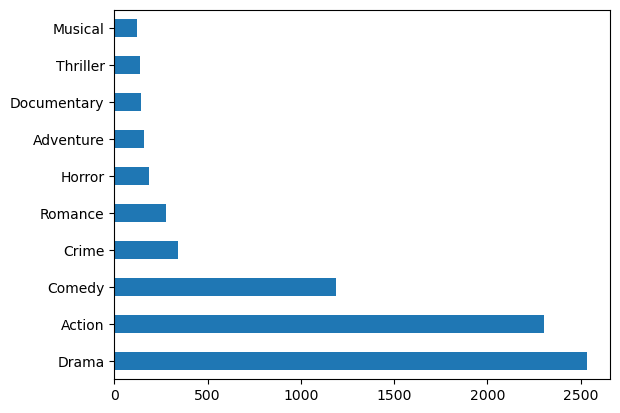

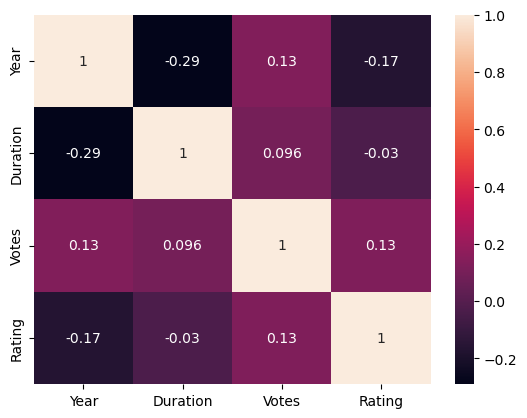

Director
Saif Ali Sayeed    10.0
Sriram Raja         9.7
Bobby Kumar         9.6
Ashish Dubey        9.4
Suhrud Godbole      9.4
Arvind Pratap       9.4
Munni Pankaj        9.4
Nikhil Mahar        9.3
Gautam Joshi        9.3
Vishwa Bhanu        9.3
Name: Rating, dtype: float64

In [17]:
#EDA 
sns.histplot(df['Rating'], bins=30, kde=True); plt.show()
df['Genre1'].value_counts().head(10).plot(kind='barh'); plt.show()
sns.heatmap(df[['Year','Duration','Votes','Rating']].corr(), annot=True); plt.show()
df.groupby('Director')['Rating'].mean().sort_values(ascending=False).head(10)

In [26]:
#feature engineering
#split the data and encode names 
#Director and actor names are text with thousands of unique values, so we replace each name with that name's average rating in the training data.
#  The split comes first, so the test data stays unseen.

from sklearn.model_selection import train_test_split

X=df[['Year','Duration','Votes','Genre1','Director','Actor 1','Actor 2', 'Actor 3']]
y=df['Rating']

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

gm = ytr.mean() # global mean, used for names the model hasn't seen
Xtr , Xte = Xtr.copy(),Xte.copy() #copy the data to avoid SettingWithCopyWarning

for c in ['Genre1','Director','Actor 1','Actor 2','Actor 3']:
    # Calculate the average rating per name(train only)
    m =ytr.groupby(Xtr[c]).mean()
    Xtr[c+'_enc']=Xtr[c].map(m)
    Xte[c+'_enc']=Xte[c].map(m).fillna(gm) #fill missing values with the global mean
    Xtr, Xte =Xtr.drop(columns=c), Xte.drop(columns=c) #drop the original column
Xtr.head()


,Year,Duration,Votes,Genre1_enc,Director_enc,Actor 1_enc,Actor 2_enc,Actor 3_enc
8157,2019.0,74.0,10,5.787435,8.150000,8.150000,8.800,8.800000
8455,1981.0,134.0,16,6.138100,5.180000,6.271622,6.260,5.719048
14490,2017.0,136.0,17774,6.138100,6.133333,5.292308,4.125,6.014286
2697,2003.0,117.0,17,5.442857,4.250000,6.166667,5.354,4.577778
15470,1988.0,120.0,33,7.605405,7.900000,6.513333,6.775,8.200000


In [28]:
#train two models and compare their performance

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {'Linear Regression': LinearRegression(),
          'Random Forest': RandomForestRegressor(200, random_state=42, n_jobs=-1)}

for name, mod in models.items():
    mod.fit(Xtr, ytr)
    p = mod.predict(Xte)
    print(name, '| MAE', round(mean_absolute_error(yte, p), 3),
          '| RMSE', round(mean_squared_error(yte, p)**0.5, 3),
          '| R2', round(r2_score(yte, p), 3))

Linear Regression | MAE 0.915 | RMSE 1.178 | R2 0.253
Random Forest | MAE 0.912 | RMSE 1.197 | R2 0.229


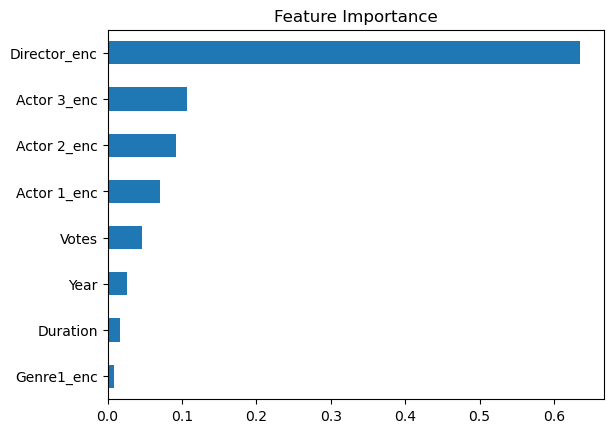

In [29]:
#for good chart
rf = models['Random Forest']
imp = pd.Series(rf.feature_importances_, index=Xtr.columns).sort_values()
imp.plot(kind='barh', title='Feature Importance')
plt.show()

Random Forest | MAE 0.798 | RMSE 1.049 | R2 0.408
Gradient Boosting | MAE 0.804 | RMSE 1.055 | R2 0.401


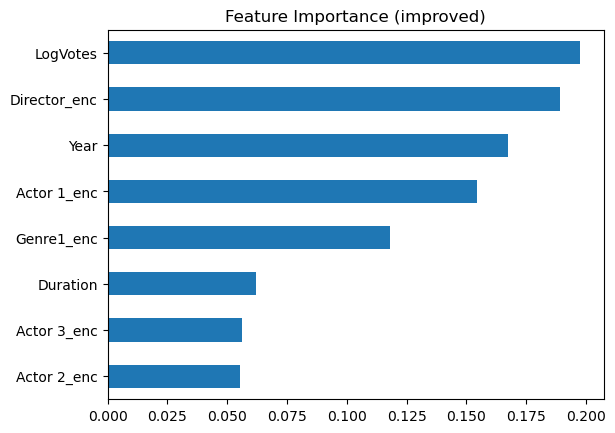

In [30]:
#improvement cell
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df['LogVotes'] = np.log1p(df['Votes'])        # votes are very skewed, so use log

cats = ['Genre1','Director','Actor 1','Actor 2','Actor 3']
X = df[['Year','Duration','LogVotes'] + cats]
y = df['Rating']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
Xtr, Xte = Xtr.copy(), Xte.copy()

gm, k = ytr.mean(), 5                          # k = smoothing strength

def smooth_map(xs, ys, col):
    g = ys.groupby(xs[col]).agg(['sum', 'count'])
    return (g['sum'] + k*gm) / (g['count'] + k)   # pulls rare names toward the global mean

kf = KFold(5, shuffle=True, random_state=42)
for c in cats:
    oof = pd.Series(index=Xtr.index, dtype=float)
    for a, b in kf.split(Xtr):                 # encode each fold using the OTHER folds
        m = smooth_map(Xtr.iloc[a], ytr.iloc[a], c)
        oof.iloc[b] = Xtr.iloc[b][c].map(m).fillna(gm).values
    Xtr[c+'_enc'] = oof
    Xte[c+'_enc'] = Xte[c].map(smooth_map(Xtr, ytr, c)).fillna(gm)

Xtr, Xte = Xtr.drop(columns=cats), Xte.drop(columns=cats)

models = {'Random Forest': RandomForestRegressor(300, min_samples_leaf=5, random_state=42, n_jobs=-1),
          'Gradient Boosting': GradientBoostingRegressor(random_state=42)}

for name, mod in models.items():
    mod.fit(Xtr, ytr)
    p = mod.predict(Xte)
    print(name, '| MAE', round(mean_absolute_error(yte, p), 3),
          '| RMSE', round(mean_squared_error(yte, p)**0.5, 3),
          '| R2', round(r2_score(yte, p), 3))

imp = pd.Series(models['Random Forest'].feature_importances_, index=Xtr.columns).sort_values()
imp.plot(kind='barh', title='Feature Importance (improved)'); plt.show()

In [ ]:
#conclusion cell
## Results & Conclusion

'''I built a regression model to predict IMDb ratings of Indian movies using
year, duration, votes, genre, director and three lead actors.

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Random Forest | 0.798 | 1.049 | 0.408 |
| Gradient Boosting | 0.804 | 1.055 | 0.401 |

**Key findings**
- The model's predictions are off by about 0.8 rating points on average.
- The most important factors are number of votes, director, release year
  and the lead actor.
- Genre and movie duration have a smaller effect.

**Improvements that made a difference**
- Out-of-fold, smoothed target encoding for director/actor/genre names raised
  R² from 0.23 to 0.41 by avoiding data leakage and reducing overfitting.
- Log-transforming Votes handled its skewed distribution.

**Limitations**
- Rating also depends on story, acting and direction quality, which are
  not in the dataset, so R² has a natural ceiling.
- About half the movies had no rating and were removed.
- Votes are only known after a movie is released, so the model estimates
  ratings of released movies and cannot forecast unreleased ones.

**Future work:** add plot/description text features (TF-IDF), try XGBoost,
and tune hyperparameters with cross-validation.'''

SyntaxError: invalid character '²' (U+00B2) (4077111214.py, line 7)

In [32]:
#demo mode
train_rows = df.loc[ytr.index]      # original training rows (with names)

def predict_movie(year, duration, votes, genre, director, actor1, actor2, actor3):
    row = {'Year': year, 'Duration': duration, 'LogVotes': np.log1p(votes)}
    names = {'Genre1': genre, 'Director': director,
             'Actor 1': actor1, 'Actor 2': actor2, 'Actor 3': actor3}
    for c, val in names.items():
        m = smooth_map(train_rows, ytr, c)
        row[c + '_enc'] = m.get(val, gm)        # unknown name -> global mean
    new = pd.DataFrame([row])[Xtr.columns]
    return round(float(models['Random Forest'].predict(new)[0]), 2)

# try it
print(predict_movie(2019, 140, 50000, 'Action', 'Rajkumar Hirani',
                    'Aamir Khan', 'Kareena Kapoor', 'Boman Irani'))

7.71
